# Time Series Analysis - Homework 4
> **Author:** Elias Schweighuber  
> **Course:** TIS


## Step 1 - Prepare the Data
We reuse the exact data preparation pipeline from Assignment 3

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, AutoETS, MSTL
from statsforecast.arima import arima_string

C:\Users\elias\PycharmProjects\notebooks\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data_dir = Path("../hw1/data")
sales_lazy = pl.scan_parquet(data_dir / "sales_combined.parquet")

all_cols = sales_lazy.collect_schema().names()
index_cols = ["item_id", "dept_id", "cat_id", "store_id", "state_id"]
date_cols = [c for c in all_cols if c not in index_cols and "2012-01-01" <= c <= "2015-12-31"]

long_sales = sales_lazy.select(index_cols + date_cols).unpivot(
    index=index_cols,
    on=date_cols,
    variable_name="date",
    value_name="sales"
)

calendar = pl.scan_csv(data_dir / "calendar.csv").select(["date", "wm_yr_wk"])
sell_prices = pl.scan_csv(data_dir / "sell_prices.csv")

dept_monthly_df = (
    long_sales
    .join(calendar, on="date", how="left")
    .join(sell_prices, on=["store_id", "item_id", "wm_yr_wk"], how="left")
    .with_columns(
        (pl.col("sales").fill_null(0).cast(pl.Float64) * pl.col("sell_price").fill_null(0.0)).alias("revenue"),
        pl.col("date").str.slice(0, 7).alias("month")
    )
    .group_by(["dept_id", "month"])
    .agg(pl.col("revenue").sum())
    .sort(["dept_id", "month"])
    .collect()
    .to_pandas()
)

df_monthly = dept_monthly_df.pivot(index="month", columns="dept_id", values="revenue")
depts = sorted(list(df_monthly.columns))
df_monthly["Total"] = df_monthly[depts].sum(axis=1)
series_names = depts + ["Total"]

# Data integrity check: 48 months x 7 departments (+ Total), no gaps, no missing values
expected_months = pd.date_range("2012-01-01", "2015-12-01", freq="MS").strftime("%Y-%m").tolist()
assert df_monthly[depts].shape == (48, 7), f"Expected (48, 7), got {df_monthly[depts].shape}"
assert list(df_monthly.index) == expected_months, "Month index has gaps!"
assert int(df_monthly.isna().sum().sum()) == 0, "Missing values found!"

## Step 2 - Fit the Models

### Models & Parameter

1. **Baselines from Assignment 3**
   - **Structural (`Seasonal Naive + Drift`)**: Best overall baseline from Assignment 3
   - **Seasonal Naive**
   - **Random Draw**

2. **Manual Statistical Models**
   - **Simple Exponential Smoothing**: Fitted with `smoothing_level` $\alpha = 0.3$. A moderate $\alpha$ smooths out month-to-month retail noise while tracking recent level shifts, producing a flat forecast.
   - **Holt-Winters**: Fitted with additive trend and additive seasonality. Additive seasonality is chosen because the seasonal amplitude stays roughly proportional to the linear growth across the years.
   - **SARIMA(p, d, q)(P, D, Q)[s]**:
     - **`SARIMA(1,1,0)(0,1,0)[12]`**: seasonal ARIMA with regular differencing ($d=1$) to remove the upward trend, seasonal differencing ($D=1, s=12$) to capture the retail cycle, and $p=1$ to capture short-term autocorrelation. If we chose a high amount of parameters with only 24 months of training data, the model would memorize random noise. For this reason we keep the parameters low
     - **`SARIMA(1,1,1)(0,1,1)[12]`**: same as with the first one, only to add q=1 and Q=1 (adjust for last months and last years unexpected error)
   - **MSTL**: decomposing each series into semi-annual ($s=6$, capturing summer/winter retail cycles) and annual ($s=12$) seasonalities plus a trend forecasted with `AutoETS`.

3. **Nixtla**
   - **`AutoARIMA(season_length=12)`**
   - **`AutoETS(season_length=12)`**


In [3]:
# from Assignment 3
def structural_forecast(y: np.ndarray, h: int = 12) -> np.ndarray:
    slope = (y[-1] - y[0]) / (len(y) - 1)
    return y[-12:].astype(float) + 12.0 * slope

def seasonal_naive_forecast(y: np.ndarray, h: int = 12) -> np.ndarray:
    return y[-12:].copy().astype(float)

def random_draw_forecast(y: np.ndarray, h: int = 12, n_sims: int = 1000, seed: int = 42) -> np.ndarray:
    rng = np.random.default_rng(seed)
    sims = rng.choice(y, size=(n_sims, h), replace=True)
    return np.mean(sims, axis=0)

# statistical model functions
def ses_forecast(y: np.ndarray, h: int = 12) -> np.ndarray:
    fit = SimpleExpSmoothing(y, initialization_method="heuristic").fit(
        smoothing_level=0.3, optimized=False
    )
    return fit.forecast(h)

def holt_winters_forecast(y: np.ndarray, h: int = 12) -> np.ndarray:
    fit = ExponentialSmoothing(
        y, trend="add", seasonal="add", seasonal_periods=12, initialization_method="estimated"
    ).fit()
    return fit.forecast(h)

def sarima_110_forecast(y: np.ndarray, h: int = 12) -> np.ndarray:
    fit = SARIMAX(
        y, order=(1, 1, 0), seasonal_order=(0, 1, 0, 12),
        enforce_stationarity=False, enforce_invertibility=False
    ).fit(disp=False)
    return fit.forecast(h)

def sarima_111_forecast(y: np.ndarray, h: int = 12) -> np.ndarray:
    fit = SARIMAX(
        y, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12),
        enforce_stationarity=False, enforce_invertibility=False
    ).fit(disp=False)
    return fit.forecast(h)

manual_models = {
    "Baseline: Structural": structural_forecast,
    "Baseline: Seasonal Naive": seasonal_naive_forecast,
    "Baseline: Random Draw": random_draw_forecast,
    "SES (alpha=0.3)": ses_forecast,
    "Holt-Winters (Add, s=12)": holt_winters_forecast,
    "SARIMA(1,1,0)(0,1,0)[12]": sarima_110_forecast,
    "SARIMA(1,1,1)(0,1,1)[12]": sarima_111_forecast,
}

def fit_all_window(df: pd.DataFrame, train_end: int, h: int = 12, window_label: str = "Validation"):
    preds = {m: {} for m in list(manual_models.keys()) + ["MSTL (s=[6,12])", "AutoARIMA", "AutoETS"]}

    # Fit manual models
    for sname in series_names:
        y_train = df[sname].iloc[:train_end].values.astype(float)
        for mname, fn in manual_models.items():
            with warnings.catch_warnings(record=True) as w_list:
                warnings.simplefilter("always")
                preds[mname][sname] = fn(y_train, h=h)

    # Fit Nixtla StatsForecast models (MSTL, AutoARIMA, AutoETS)
    dates = pd.date_range("2012-01-01", periods=train_end, freq="MS")
    sf_df = pd.DataFrame([
        {"unique_id": sname, "ds": d, "y": float(val)}
        for sname in series_names
        for d, val in zip(dates, df[sname].iloc[:train_end].values)
    ])

    sf = StatsForecast(
        models=[
            MSTL(season_length=[6, 12]),
            AutoARIMA(season_length=12),
            AutoETS(season_length=12),
        ],
        freq="MS",
        n_jobs=1,
    )
    sf.fit(sf_df)
    sf_fc = sf.predict(h=h)

    for sname in series_names:
        sub = sf_fc[sf_fc["unique_id"] == sname]
        preds["MSTL (s=[6,12])"][sname] = sub["MSTL"].values.astype(float)
        preds["AutoARIMA"][sname] = sub["AutoARIMA"].values.astype(float)
        preds["AutoETS"][sname] = sub["AutoETS"].values.astype(float)

    # Extract detected parameters from AutoARIMA and AutoETS
    uid_order = sf.uids.tolist()
    param_rows = []
    for i, sname in enumerate(uid_order):
        aa_mod = sf.fitted_[i, 1].model_
        ae_mod = sf.fitted_[i, 2].model_
        param_rows.append({
            "Series": sname,
            f"AutoARIMA ({window_label})": arima_string(aa_mod).strip(),
            f"AutoETS ({window_label})": f"{ae_mod.get('method')} (alpha={ae_mod.get('par', [np.nan])[0]:.2f})",
        })
    param_df = pd.DataFrame(param_rows).set_index("Series").loc[series_names]
    return preds, param_df

val_preds, val_params = fit_all_window(df_monthly, train_end=24, h=12, window_label="Val 24m")
test_preds, test_params = fit_all_window(df_monthly, train_end=36, h=12, window_label="Test 36m")


print("PARAMETERS DETECTED BY NIXTLA AUTOARIMA & AUTOETS")
detected_params = val_params.join(test_params)
display(detected_params)


PARAMETERS DETECTED BY NIXTLA AUTOARIMA & AUTOETS


,AutoARIMA (Val 24m),AutoETS (Val 24m),AutoARIMA (Test 36m),AutoETS (Test 36m)
Series,,,,
FOODS_1,"ARIMA(0,1,1) with drift","ETS(M,Ad,N) (alpha=0.00)","ARIMA(1,1,0)(0,1,1)[12]","ETS(M,Ad,N) (alpha=0.00)"
FOODS_2,"ARIMA(1,0,0) with non-zero mean","ETS(M,N,N) (alpha=0.65)","ARIMA(0,1,3)(0,0,1)[12]","ETS(A,N,N) (alpha=0.66)"
FOODS_3,"ARIMA(1,0,0) with non-zero mean","ETS(A,N,N) (alpha=0.91)","ARIMA(0,0,1)(0,1,1)[12] with drift","ETS(A,N,N) (alpha=0.85)"
HOBBIES_1,"ARIMA(0,1,0) with drift","ETS(M,Ad,N) (alpha=0.00)","ARIMA(1,1,0)(0,0,1)[12] with drift","ETS(M,Ad,N) (alpha=0.45)"
HOBBIES_2,"ARIMA(0,1,1) with drift","ETS(M,A,N) (alpha=0.00)","ARIMA(0,1,0)(0,0,1)[12]","ETS(M,N,N) (alpha=0.69)"
HOUSEHOLD_1,"ARIMA(0,1,0)","ETS(A,N,N) (alpha=1.00)","ARIMA(1,1,0)(0,1,0)[12]","ETS(A,N,N) (alpha=1.00)"
HOUSEHOLD_2,"ARIMA(1,0,0) with non-zero mean","ETS(A,N,N) (alpha=1.00)","ARIMA(0,0,2)(0,1,0)[12] with drift","ETS(A,N,N) (alpha=0.91)"
Total,"ARIMA(0,1,0)","ETS(A,N,N) (alpha=0.74)","ARIMA(0,1,0)(0,1,0)[12]","ETS(A,N,N) (alpha=0.66)"


### Comparison: Manual Parameters vs. Nixtla `AutoARIMA` and `AutoETS`
- **24-Month Validation Window**: Because 24 months equals exactly two seasonal cycles (2 * 12), both `AutoARIMA` and `AutoETS` refuse to estimate 12-month seasonal states
- **36-Month Test Window**: Once a third seasonal cycle is available, `AutoARIMA` detects $s=12$ seasonality. The selected ARIMA directly matches the manually chosen `SARIMA(1,1,0)(0,1,0)[12]` specification. Meanwhile, `AutoETS` still avoids adding seasonal states.


## Step 3 - One Results Table

In [4]:
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray, y_train: np.ndarray) -> dict:
    err = y_true - y_pred
    mae = float(np.mean(np.abs(err)))
    rmse = float(np.sqrt(np.mean(err ** 2)))
    mape = float(np.mean(np.abs(err / y_true)) * 100.0)
    wmape = float(np.sum(np.abs(err)) / np.sum(y_true) * 100.0)

    ss_res = np.sum(err ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = float(1.0 - ss_res / ss_tot) if ss_tot != 0 else np.nan
    bias = float(np.mean(y_pred - y_true))

    scale = float(np.mean(np.abs(y_train[12:] - y_train[:-12])))
    mase = float(mae / scale) if scale != 0 else np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "wMAPE (%)": wmape,
        "R2": r2,
        "bias": bias,
        "MASE": mase,
    }

all_models_sorted = sorted(list(test_preds.keys()))
rows = []

# Seven departments sorted alphabetically, then Total as an extra block at the bottom
for sname in depts + ["Total"]:
    y_train_val = df_monthly[sname].iloc[:24].values
    y_true_val = df_monthly[sname].iloc[24:36].values
    y_train_test = df_monthly[sname].iloc[:36].values
    y_true_test = df_monthly[sname].iloc[36:48].values

    dept_rows = []
    for mname in all_models_sorted:
        m_val = compute_metrics(y_true_val, val_preds[mname][sname], y_train_val)
        m_test = compute_metrics(y_true_test, test_preds[mname][sname], y_train_test)
        dept_rows.append({
            "Department": sname,
            "Model": mname,
            "MAE": m_test["MAE"],
            "RMSE": m_test["RMSE"],
            "MAPE (%)": m_test["MAPE (%)"],
            "wMAPE (%)": m_test["wMAPE (%)"],
            "Val wMAPE (%)": m_val["wMAPE (%)"],
            "R2": m_test["R2"],
            "bias": m_test["bias"],
            "MASE": m_test["MASE"],
        })

    # Identify best model on Test and Validation per department (lowest wMAPE)
    best_test_model = min(dept_rows, key=lambda r: r["wMAPE (%)"])["Model"]
    best_val_model = min(dept_rows, key=lambda r: r["Val wMAPE (%)"])["Model"]
    for r in dept_rows:
        tags = []
        if r["Model"] == best_test_model:
            tags.append("★ Best Test")
        if r["Model"] == best_val_model:
            tags.append("◆ Best Val")
        r["Best"] = " / ".join(tags)
        rows.extend([r])

results_df = pd.DataFrame(rows).set_index(["Department", "Model"])

formatted_results = pd.DataFrame(index=results_df.index)
formatted_results["MAE"] = results_df["MAE"].map(lambda x: f"${x:,.2f}")
formatted_results["RMSE"] = results_df["RMSE"].map(lambda x: f"${x:,.2f}")
formatted_results["MAPE (%)"] = results_df["MAPE (%)"].map(lambda x: f"{x:.2f}%")
formatted_results["wMAPE (%)"] = results_df["wMAPE (%)"].map(lambda x: f"{x:.2f}%")
formatted_results["Val wMAPE (%)"] = results_df["Val wMAPE (%)"].map(lambda x: f"{x:.2f}%")
formatted_results["R2"] = results_df["R2"].map(lambda x: f"{x:.3f}")
formatted_results["bias"] = results_df["bias"].map(lambda x: f"${x:,.2f}")
formatted_results["MASE"] = results_df["MASE"].map(lambda x: f"{x:.3f}")
formatted_results["Best"] = results_df["Best"]

pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 140)
display(formatted_results)


MAE         RMSE MAPE (%) wMAPE (%) Val wMAPE (%)       R2          bias   MASE         Best
Department  Model                                                                                                                         
FOODS_1     AutoARIMA                  $15,091.77   $17,222.03    6.20%     6.22%         9.37%   -0.124   $-11,923.40  1.317             
            AutoETS                    $28,086.10   $32,437.79   11.18%    11.58%         4.44%   -2.987   $-28,085.77  2.451             
            Baseline: Random Draw      $35,217.53   $38,785.08   14.14%    14.53%         5.86%   -4.700   $-35,217.53  3.074             
            Baseline: Seasonal Naive   $28,135.21   $31,045.07   11.43%    11.60%         3.98%   -2.652   $-28,135.21  2.456             
            Baseline: Structural       $11,011.05   $13,142.60    4.64%     4.54%        14.17%    0.345       $722.25  0.961  ★ Best Test
            Holt-Winters (Add, s=12)   $20,331.64   $22,426.26    8.31%     8.39%         4.28%   -0.906   $-18,783.64  1.775             
            MSTL (s=[6,12])            $28,941.67   $31,237.63   11.76%    11.94%         3.04%   -2.698   $-28,759.42  2.526   ◆ Best Val
            SARIMA(1,1,0)(0,1,0)[12]   $17,744.90   $20,906.13    7.21%     7.32%         3.66%   -0.656   $-15,870.00  1.549             
            SARIMA(1,1,1)(0,1,1)[12]   $13,569.30   $18,020.05    5.87%     5.60%         3.65%   -0.230    $12,877.65  1.184             
            SES (alpha=0.3)            $20,441.13   $24,927.15    8.09%     8.43%         4.65%   -1.355   $-18,906.75  1.784             
FOODS_2     AutoARIMA                  $21,357.97   $26,315.24    4.19%     4.37%        10.67%    0.668   $-18,067.21  0.509             
            AutoETS                    $46,932.31   $60,803.03    9.04%     9.59%        13.08%   -0.774   $-40,155.12  1.119             
            Baseline: Random Draw     $116,430.18  $124,929.33   23.15%    23.80%        10.34%   -6.487  $-116,430.18  2.777   ◆ Best Val
            Baseline: Seasonal Naive   $90,195.15   $91,333.64   18.42%    18.44%        12.07%   -3.002   $-90,195.15  2.151             
            Baseline: Structural       $62,718.62   $64,345.12   12.76%    12.82%        12.45%   -0.986   $-62,718.62  1.496             
            Holt-Winters (Add, s=12)   $40,964.50   $53,561.29    8.01%     8.37%        12.68%   -0.376   $-19,122.37  0.977             
            MSTL (s=[6,12])            $48,082.23   $59,150.64    9.39%     9.83%        12.31%   -0.678   $-32,724.58  1.147             
            SARIMA(1,1,0)(0,1,0)[12]   $15,906.80   $19,748.78    3.40%     3.25%        13.21%    0.813    $13,537.43  0.379  ★ Best Test
            SARIMA(1,1,1)(0,1,1)[12]  $293,146.45  $298,478.64   61.47%    59.92%        13.54%  -41.737   $293,146.45  6.992             
            SES (alpha=0.3)            $59,204.70   $72,041.89   11.47%    12.10%        11.05%   -1.490   $-55,726.65  1.412             
FOODS_3     AutoARIMA                  $78,198.87   $86,160.91    6.46%     6.42%         9.48%   -1.333    $60,981.25  0.929             
            AutoETS                    $63,280.30   $80,760.50    5.03%     5.20%         8.10%   -1.050   $-57,799.23  0.752             
            Baseline: Random Draw      $62,746.51   $79,840.07    4.99%     5.15%         8.84%   -1.004   $-56,026.86  0.745             
            Baseline: Seasonal Naive   $43,922.18   $50,912.74    3.62%     3.61%         7.13%    0.185    $10,750.78  0.522             
            Baseline: Structural       $77,783.42   $91,267.76    6.43%     6.39%         4.70%   -1.618    $76,506.70  0.924   ◆ Best Val
            Holt-Winters (Add, s=12)   $62,448.40   $72,341.44    5.15%     5.13%         4.75%   -0.645    $39,598.83  0.742             
            MSTL (s=[6,12])            $38,753.21   $52,478.19    3.17%     3.18%         4.89%    0.134    $-5,998.46  0.460  ★ Best Test
            SAR

In [5]:
# Summary of Validation Winner vs. Test Winner per Department
summary_picks = []
for sname in depts + ["Total"]:
    sub = results_df.loc[sname]
    val_winner = sub["Val wMAPE (%)"].idxmin()
    test_winner = sub["wMAPE (%)"].idxmin()
    summary_picks.append({
        "Department": sname,
        "Validation Winner (2014)": val_winner,
        "Val Winner Val wMAPE": f"{sub.loc[val_winner, 'Val wMAPE (%)']:.2f}%",
        "Val Winner Test wMAPE": f"{sub.loc[val_winner, 'wMAPE (%)']:.2f}%",
        "Test Winner (2015)": test_winner,
        "Test Winner Test wMAPE": f"{sub.loc[test_winner, 'wMAPE (%)']:.2f}%",
        "Held in Test?": "Yes" if val_winner == test_winner else "No",
    })
display(pd.DataFrame(summary_picks).set_index("Department"))


,Validation Winner (2014),Val Winner Val wMAPE,Val Winner Test wMAPE,Test Winner (2015),Test Winner Test wMAPE,Held in Test?
Department,,,,,,
FOODS_1,"MSTL (s=[6,12])",3.04%,11.94%,Baseline: Structural,4.54%,No
FOODS_2,Baseline: Random Draw,10.34%,23.80%,"SARIMA(1,1,0)(0,1,0)[12]",3.25%,No
FOODS_3,Baseline: Structural,4.70%,6.39%,"MSTL (s=[6,12])",3.18%,No
HOBBIES_1,SES (alpha=0.3),3.58%,22.38%,Baseline: Structural,13.92%,No
HOBBIES_2,"SARIMA(1,1,0)(0,1,0)[12]",17.53%,36.98%,Baseline: Structural,12.06%,No
HOUSEHOLD_1,"MSTL (s=[6,12])",2.63%,12.94%,Baseline: Structural,6.15%,No
HOUSEHOLD_2,"MSTL (s=[6,12])",3.84%,9.07%,"SARIMA(1,1,1)(0,1,1)[12]",3.68%,No
Total,"SARIMA(1,1,0)(0,1,0)[12]",2.19%,4.00%,Baseline: Structural,3.23%,No


## Step 4 - One Plot

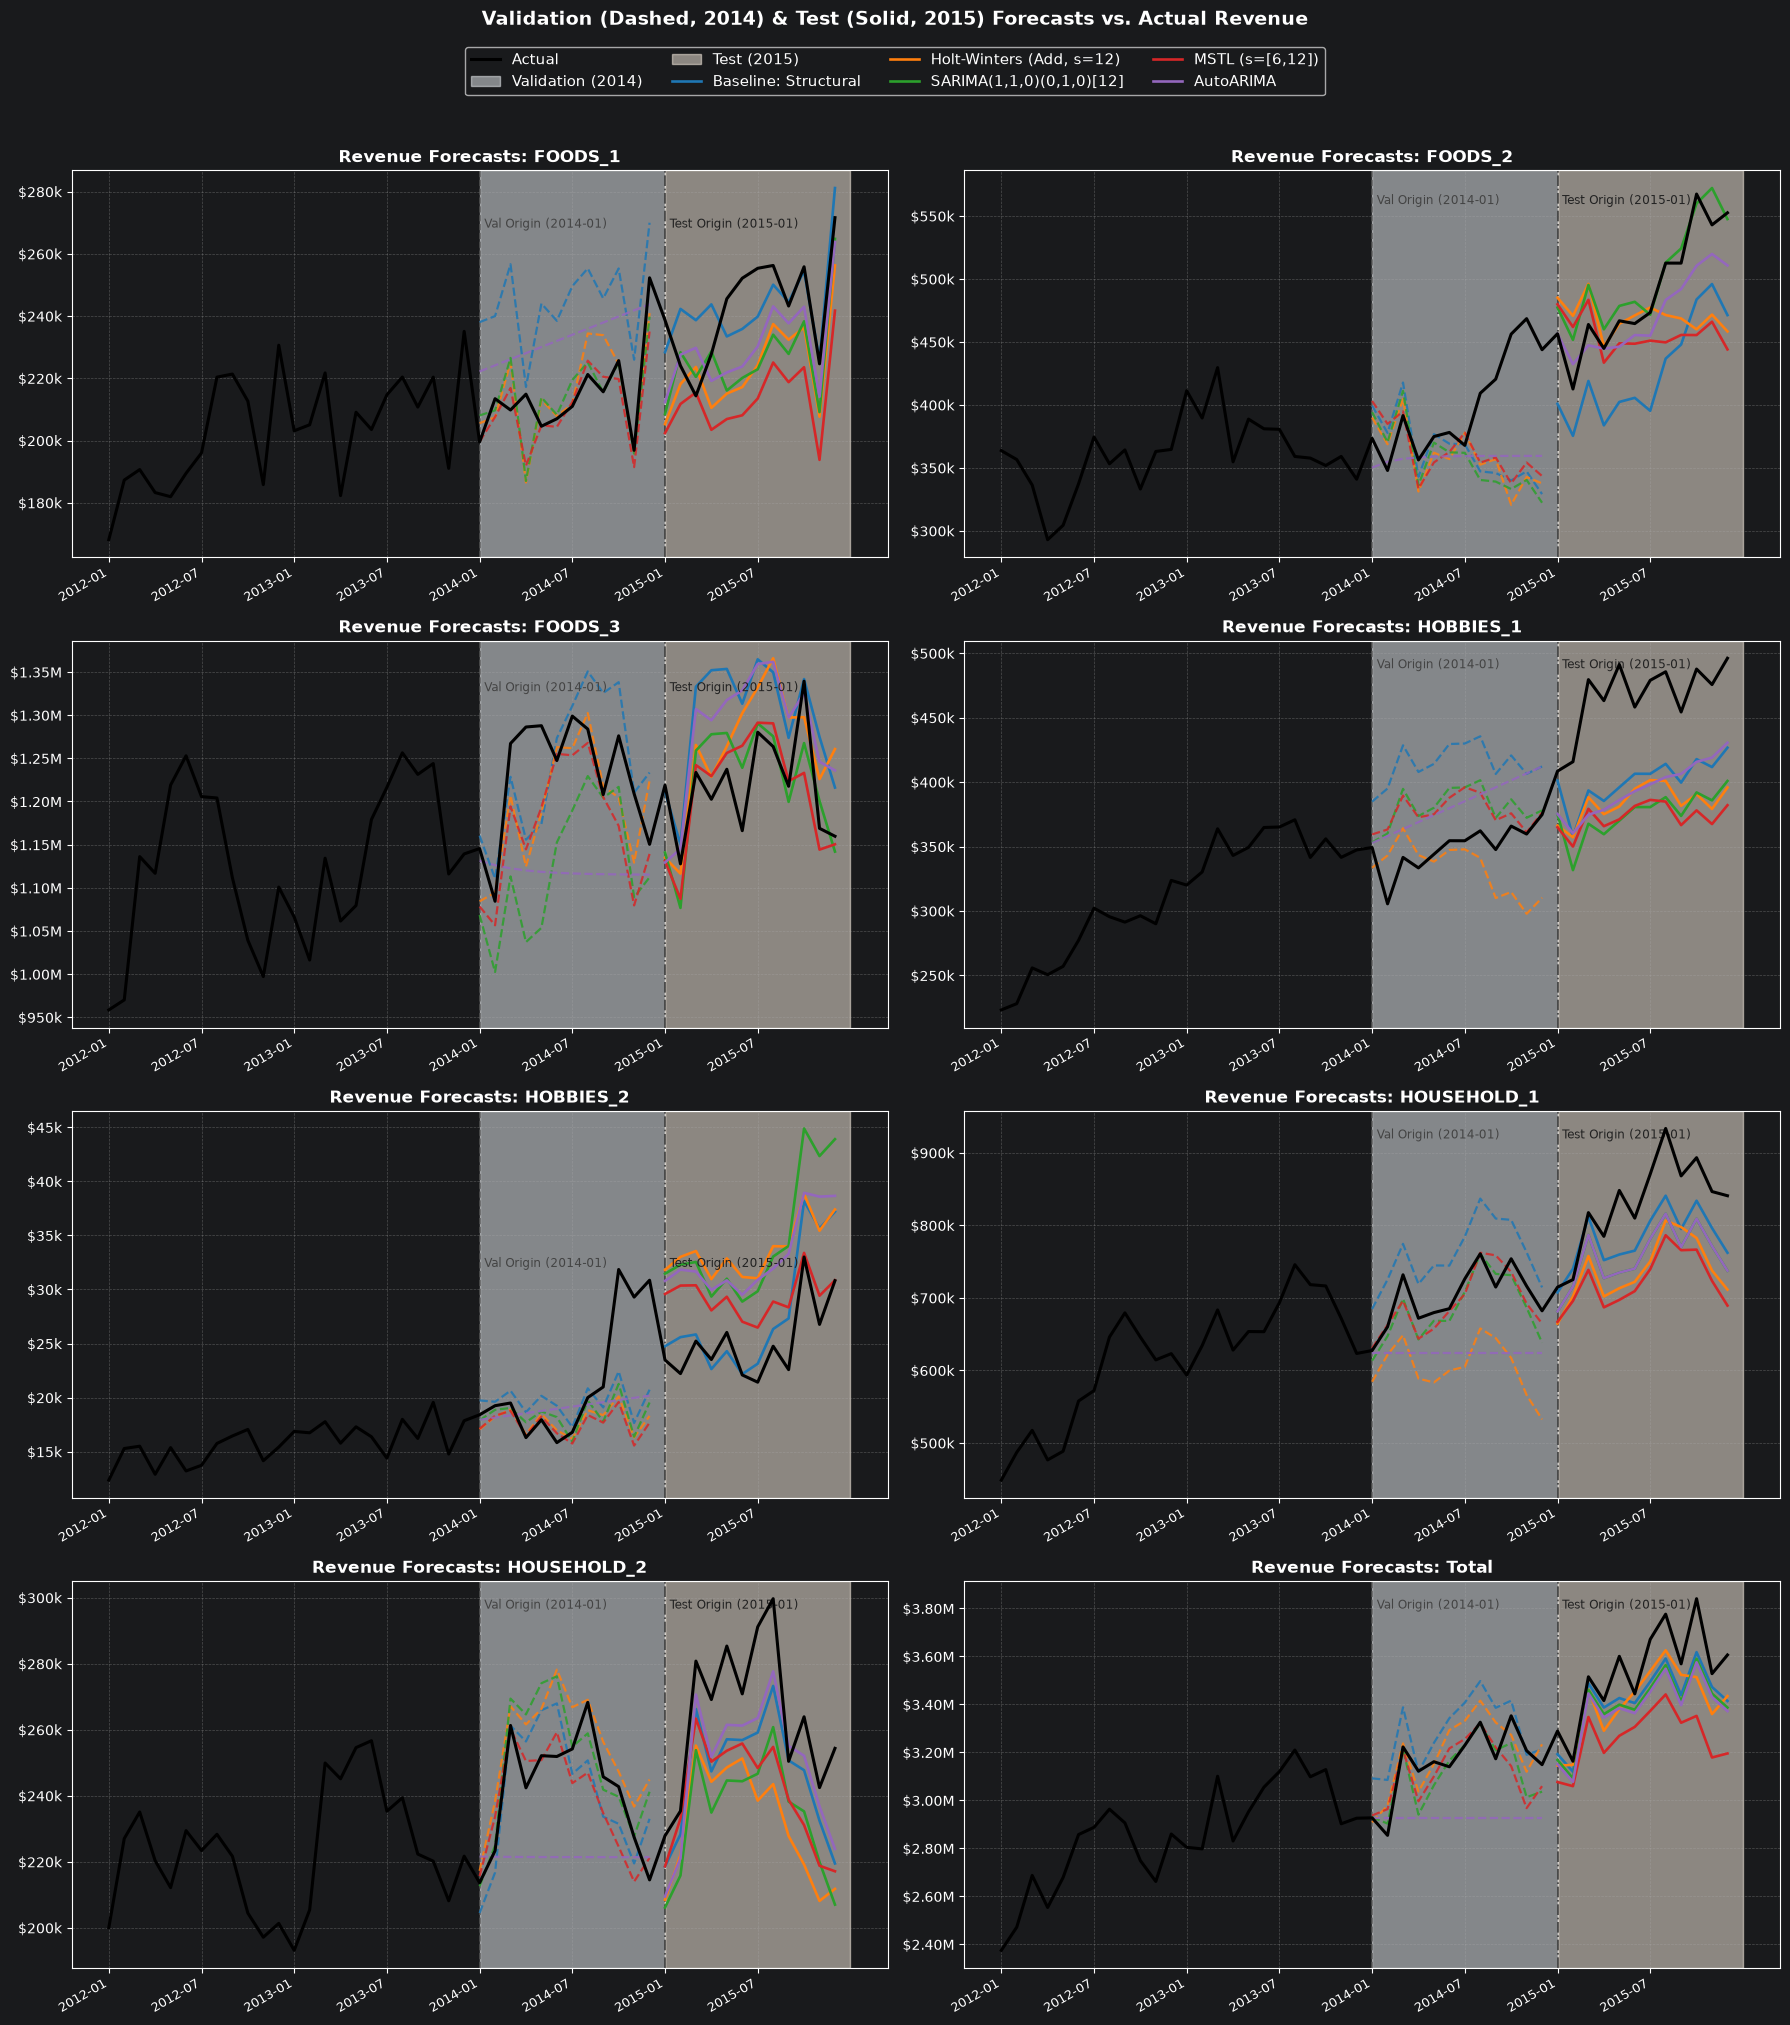

In [6]:
plot_models = [
    "Baseline: Structural",
    "Holt-Winters (Add, s=12)",
    "SARIMA(1,1,0)(0,1,0)[12]",
    "MSTL (s=[6,12])",
    "AutoARIMA",
]

model_colors = {
    "Baseline: Structural": "#1f77b4",
    "Holt-Winters (Add, s=12)": "#ff7f0e",
    "SARIMA(1,1,0)(0,1,0)[12]": "#2ca02c",
    "MSTL (s=[6,12])": "#d62728",
    "AutoARIMA": "#9467bd",
}

months = df_monthly.index.tolist()
x_all = np.arange(48)
x_val = np.arange(24, 36)
x_test = np.arange(36, 48)

fig, axes = plt.subplots(4, 2, figsize=(18, 20), sharex=False)
axes = axes.flatten()

for idx, sname in enumerate(series_names):
    ax = axes[idx]
    y_actual = df_monthly[sname].values

    # Actual series
    ax.plot(x_all, y_actual, color="black", linewidth=2.2, label="Actual", zorder=5)

    # Mark the two forecast origins
    ax.axvline(x=24, color="#555555", linestyle="--", linewidth=1.2, alpha=0.8)
    ax.axvline(x=36, color="#222222", linestyle="-.", linewidth=1.2, alpha=0.8)
    ax.axvspan(24, 36, color="#f0f4f8", alpha=0.5, label="Validation (2014)" if idx == 0 else None)
    ax.axvspan(36, 48, color="#fff4e6", alpha=0.5, label="Test (2015)" if idx == 0 else None)

    y_min, y_max = y_actual.min(), y_actual.max()
    ax.text(24.3, y_max, "Val Origin (2014-01)", fontsize=8.5, color="#444444", va="top", ha="left")
    ax.text(36.3, y_max, "Test Origin (2015-01)", fontsize=8.5, color="#222222", va="top", ha="left")

    # Plot the 5 selected models in both Validation (dashed) and Test (solid) windows
    for mname in plot_models:
        c = model_colors[mname]
        # Validation forecast (dashed)
        ax.plot(x_val, val_preds[mname][sname], color=c, linestyle="--", linewidth=1.6, alpha=0.85)
        # Test forecast (solid, labeled for legend)
        ax.plot(x_test, test_preds[mname][sname], color=c, linestyle="-", linewidth=1.9, label=mname)

    ax.set_title(f"Revenue Forecasts: {sname}", fontsize=12, fontweight="bold", pad=6)
    ax.set_xticks(range(0, 48, 6))
    ax.set_xticklabels([months[i] for i in range(0, 48, 6)], rotation=30, ha="right", fontsize=9)
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda v, p: f"${v*1e-3:,.0f}k" if abs(v) < 1e6 else f"${v*1e-6:,.2f}M")
    )
    ax.grid(True, linestyle="--", alpha=0.35)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center", bbox_to_anchor=(0.5, 0.995),
    ncol=4, fontsize=10.5, frameon=True
)
fig.suptitle("Validation (Dashed, 2014) & Test (Solid, 2015) Forecasts vs. Actual Revenue", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout(rect=[0, 0, 1, 0.965])
plt.show()
